In [39]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import sklearn as sk

In [40]:
class LinearRegression(torch.nn.Module):
    def __init__(self, input_dim):
        super(LinearRegression, self).__init__()
        self.linear = torch.nn.Linear(input_dim, 1)

    def forward(self, x):
        return self.linear(x)

In [41]:
# Toy dataset: y = 3x + 2 + noise
torch.manual_seed(0)

x = torch.linspace(-5, 5, 100).reshape(-1, 1)
y = 3 * x + 2 + 0.5 * torch.randn_like(x)
x, y

(tensor([[-5.0000],
         [-4.8990],
         [-4.7980],
         [-4.6970],
         [-4.5960],
         [-4.4949],
         [-4.3939],
         [-4.2929],
         [-4.1919],
         [-4.0909],
         [-3.9899],
         [-3.8889],
         [-3.7879],
         [-3.6869],
         [-3.5859],
         [-3.4848],
         [-3.3838],
         [-3.2828],
         [-3.1818],
         [-3.0808],
         [-2.9798],
         [-2.8788],
         [-2.7778],
         [-2.6768],
         [-2.5758],
         [-2.4747],
         [-2.3737],
         [-2.2727],
         [-2.1717],
         [-2.0707],
         [-1.9697],
         [-1.8687],
         [-1.7677],
         [-1.6667],
         [-1.5657],
         [-1.4646],
         [-1.3636],
         [-1.2626],
         [-1.1616],
         [-1.0606],
         [-0.9596],
         [-0.8586],
         [-0.7576],
         [-0.6566],
         [-0.5556],
         [-0.4545],
         [-0.3535],
         [-0.2525],
         [-0.1515],
         [-0.0505],


In [42]:
learning_rate = 0.01
model = LinearRegression(input_dim=x.shape[1])
criterion = torch.nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

num_epochs = 1000

for epoch in range(num_epochs):
    # Forward pass
    outputs = model(x)
    loss = criterion(outputs, y)

    # Backward pass and optimization
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if (epoch+1) % 100 == 0:
        print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')

# Print learned parameters
print(f'Learned weight: {model.linear.weight.item():.4f}, Learned bias: {model.linear.bias.item():.4f}')


Epoch [100/1000], Loss: 0.3337
Epoch [200/1000], Loss: 0.2636
Epoch [300/1000], Loss: 0.2624
Epoch [400/1000], Loss: 0.2624
Epoch [500/1000], Loss: 0.2624
Epoch [600/1000], Loss: 0.2624
Epoch [700/1000], Loss: 0.2624
Epoch [800/1000], Loss: 0.2624
Epoch [900/1000], Loss: 0.2624
Epoch [1000/1000], Loss: 0.2624
Learned weight: 2.9999, Learned bias: 2.0186


In [43]:
# evaluation
with torch.no_grad():
    predicted = model(x)
    mse = criterion(predicted, y)
    print(f'Mean Squared Error on training data: {mse.item():.4f}')
    print(f'Learned weight: {model.linear.weight.item():.4f}, Learned bias: {model.linear.bias.item():.4f}')

Mean Squared Error on training data: 0.2624
Learned weight: 2.9999, Learned bias: 2.0186


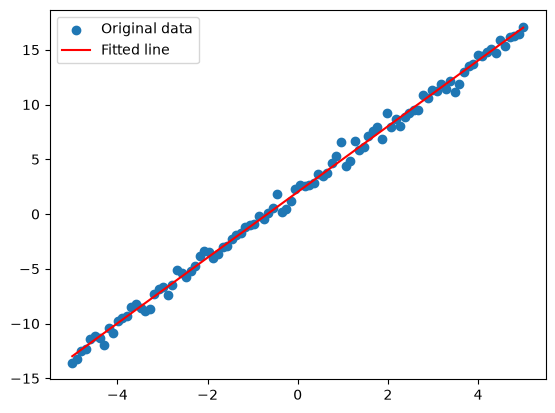

In [44]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.scatter(x.numpy(), y.numpy(), label='Original data')
plt.plot(x.numpy(), predicted.numpy(), label='Fitted line', color='r')
plt.legend()
plt.show()